# Session 4: Convolutional Neural Networks and Filters

This notebook contains structured tasks based on Session 4 materials.

**Instructions:**
- Do NOT use a separate `.py` file. Complete all tasks directly in this notebook.
- Keep your code clear and well-commented.
- For Visulaization, please use `%matplotlib inline`
- Submit your completed notebook by uploading it to your forked repository.

### ***DO NOT UPLOAD THE DATASET TO GITHUB as it's too large***
<hr>

## Task 1: Convolutional Filters on an Image
Apply several 2D filters (Sobel X, Sobel Y, Laplacian, and Sharpen) to an image and visualize the results side by side.

**Hint:**
- Use OpenCV (`cv2.filter2D`) or NumPy to apply kernels.
- Define common kernels (Sobel, Laplacian, Sharpen).
- Use `matplotlib.pyplot` to plot the original and filtered images.

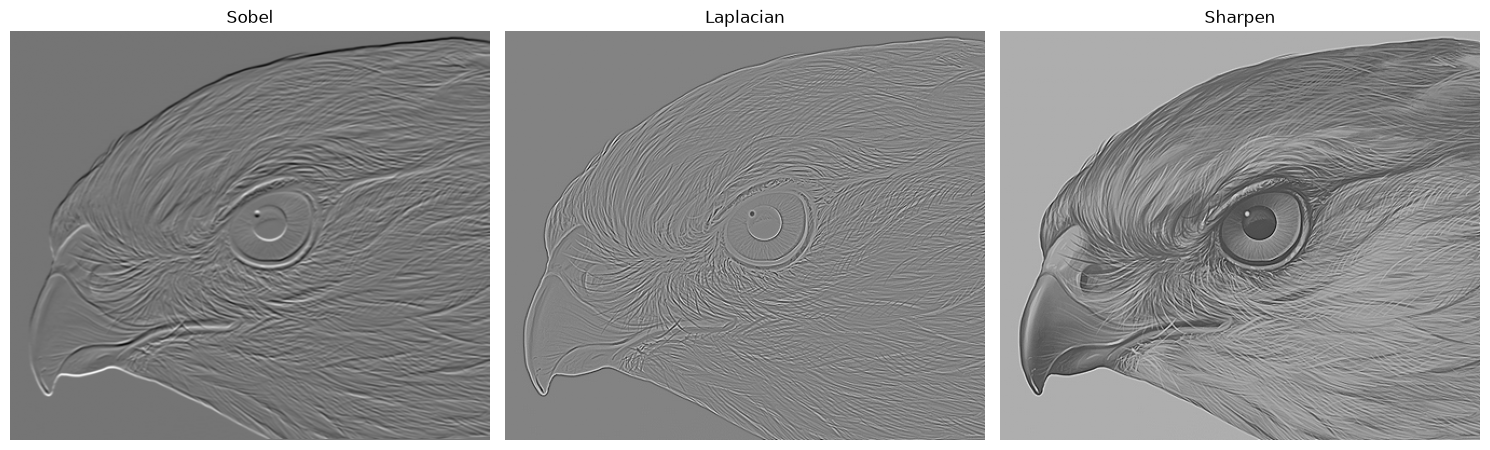

In [4]:
# TODO: Load an image (use OpenCV or matplotlib)
import cv2
import numpy as np
import matplotlib.pyplot as plt

path = r"D:\Documents\term\Skyxpert\cv\SkyXperts-Vision-Course-master\Session2\images\hawk.png"
# TODO: Convert to grayscale
img = cv2.imread(path, 0)  # Use grayscale for filtering

# TODO: Define Sobel, Laplacian, and Sharpen kernels
sobel_kernel = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
laplacian_kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])

# TODO: Apply each filter to the image
sobel = cv2.filter2D(img, cv2.CV_64F, sobel_kernel)
laplacian = cv2.filter2D(img, cv2.CV_64F, laplacian_kernel)
sharpen = cv2.filter2D(img, cv2.CV_64F, sharpen_kernel)

# TODO: Plot results in a grid using matplotlib
plt.figure(figsize=(15, 10))

results = [
    (sobel, "Sobel"),
    (laplacian, "Laplacian"),
    (sharpen, "Sharpen")
]

for i, (image, title) in enumerate(results):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Task 2: Build a Simple CNN on FashionMNIST
Construct and train a small Convolutional Neural Network (CNN) on the FashionMNIST dataset.

**Hint:**
- Use `torchvision.datasets.FashionMNIST` for loading data.
- Define a small CNN with `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, and `nn.Linear`.
- Train for a few epochs using an optimizer (e.g., Adam) and loss function (e.g., CrossEntropyLoss).
- Print training accuracy after each epoch.

In [5]:
import sys

print(sys.executable)
print(sys.version)

c:\Python314\python.exe
3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]


In [7]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)
# TODO: Load FashionMNIST dataset with transforms
# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download training dataset
train_dataset = datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Download testing dataset
test_dataset = datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

# TODO: Define a simple CNN class with one conv layer and one fc layer
class SimpleCNN(nn.Module):

    def __init__(self):
        super(SimpleCNN, self).__init__()

        # First convolutional layer
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3
        )

        # Activation function
        self.relu = nn.ReLU()

        # Max pooling layer
        self.pool = nn.MaxPool2d(kernel_size=2)

        # Fully connected output layer
        self.fc = nn.Linear(16 * 13 * 13, 10)

    def forward(self, x):

        # Convolution
        x = self.conv1(x)

        # ReLU activation
        x = self.relu(x)

        # Max pooling
        x = self.pool(x)

        # Flatten feature maps
        x = x.view(x.size(0), -1)

        # Classification
        x = self.fc(x)

        return x


# Create CNN model
net = SimpleCNN().to(device)

print(net)

# TODO: Set up optimizer and loss function
# Cross Entropy Loss for classification
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = optim.Adam(
    net.parameters(),
    lr=0.001
)

# TODO: Implement a short training loop (2-3 epochs)
epochs = 3

for epoch in range(epochs):

    net.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = net(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

        # Calculate predictions
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {running_loss / len(train_loader):.4f} "
        f"Accuracy: {accuracy:.2f}%"
    )

Using device: cpu


100.0%
100.0%
100.0%
100.0%


Training images: 60000
Testing images: 10000
SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=2704, out_features=10, bias=True)
)
Epoch [1/3] Loss: 0.4827 Accuracy: 83.58%
Epoch [2/3] Loss: 0.3343 Accuracy: 88.33%
Epoch [3/3] Loss: 0.3010 Accuracy: 89.40%


## Task 3: Visualize Feature Maps
Visualize feature maps produced by the first convolutional layer of your CNN.

**Hint:**
- Take a single image from the test set.
- Pass it through the first convolutional layer (`net.conv1`).
- Convert the output to NumPy and plot several channels as images.

Feature maps shape: (16, 26, 26)
Original label: 9


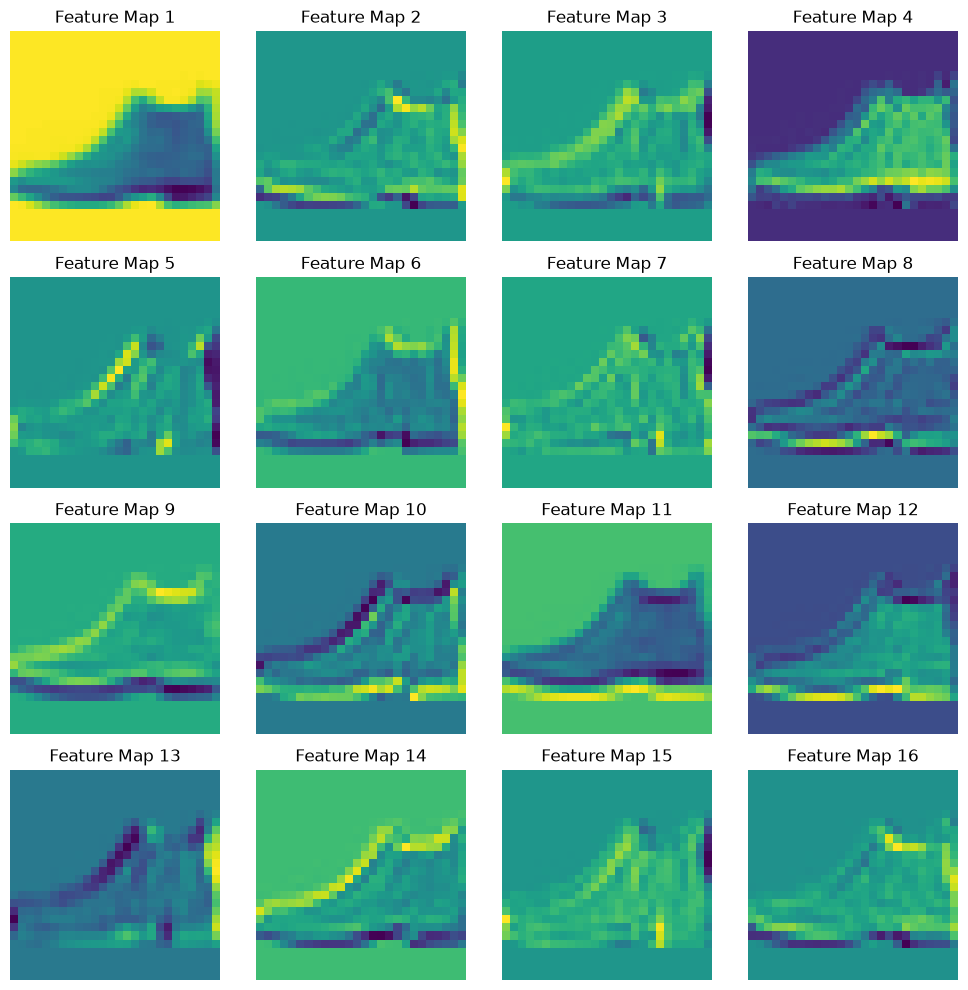

In [8]:
# TODO: Take one test image
# Set model to evaluation mode
net.eval()

# Get one image from test dataset
test_image, label = test_dataset[0]

# Add batch dimension
test_image = test_image.unsqueeze(0).to(device)

# Pass image through first convolutional layer
with torch.no_grad():

    feature_maps = net.conv1(test_image)

# Convert feature maps to NumPy
feature_maps = feature_maps.squeeze(0).cpu().numpy()

print("Feature maps shape:", feature_maps.shape)
print("Original label:", label)
# Display first 16 feature maps
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):

    ax.imshow(feature_maps[i], cmap='viridis')
    ax.set_title(f'Feature Map {i + 1}')
    ax.axis('off')

plt.tight_layout()
plt.show()
# TODO: Forward pass through the first convolutional layer
# TODO: Convert feature maps to NumPy array
# TODO: Plot the first few feature maps in a grid

## Task 4: Haar Cascade Face Detection

Apply Haar Cascade classifiers for basic object detection (faces).

**Hint:**
- Use `cv2.CascadeClassifier` with a pre-trained XML file (e.g., `haarcascade_frontalface_default.xml`).
- Convert the input image to grayscale before detection.
- Use `detectMultiScale` to get bounding boxes.
- Draw rectangles on detected faces with `cv2.rectangle`.
- Visualize with Matplotlib.


In [11]:
import cv2

print("OpenCV version:", cv2.__version__)
print("OpenCV location:", cv2.__file__)
print("CascadeClassifier available:", hasattr(cv2, 'CascadeClassifier'))

OpenCV version: 5.0.0
OpenCV location: C:\Users\rrrrrrrr\AppData\Roaming\Python\Python314\site-packages\cv2\__init__.py
CascadeClassifier available: False


In [12]:
%pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [13]:
%pip install opencv-python==4.14.0.94

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/41.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/41.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/41.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/41.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/41.2 MB ? eta -:--:--
    --------------------------------------- 0.5/41.2 MB 571.5 kB/s eta 0:01:12
    --------------------------------------- 0.8/41.2 MB 873.7 kB/s eta 0:00:47
   - -------------------------------------- 1.0/41.2 MB 996.1 kB/s eta 0:00:41
   - -------------------------------------- 1.0/41.2 MB 996.1 kB/s eta 0:00:41
   - -------------------------------------- 1.3/41.2 MB 875.2 kB/s eta 0:00:46
   - -------------------------------------- 1.3/41.2 MB 875.2 kB/s eta 0:00:46
   - -------------------------------------- 1.6/41.2 MB 825.5 kB/s eta 0:00:48
   - --------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, 'CascadeClassifier'))

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

print("Cascade loaded:", not face_cascade.empty())

OpenCV version: 4.14.0
CascadeClassifier available: True
Cascade loaded: True


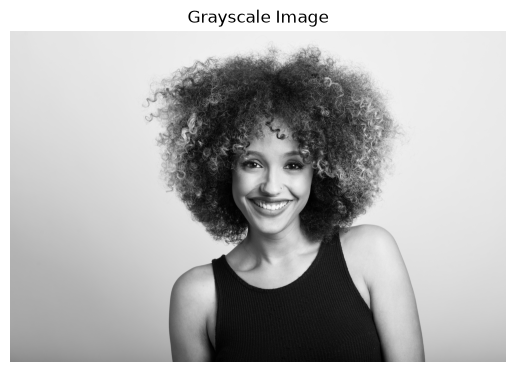

Number of faces detected: 6


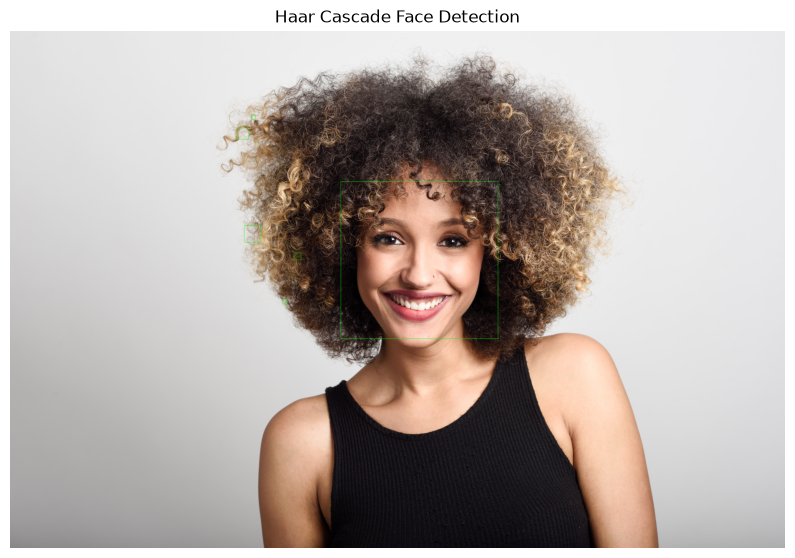

In [3]:
# TODO: Load an image containing a face
# Load image
import matplotlib.pyplot as plt

%matplotlib inline

image = cv2.imread(r'D:\Documents\term\Skyxpert\cv\SkyXperts-Vision-Course-master\Session4\Convolutional_Filters_Edge_Detection\images\face2.jpg')

if image is None:
    raise FileNotFoundError("Image not found. Check the image path.")

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')
plt.show()
# TODO: Convert to grayscale
# TODO: Load Haar Cascade XML (frontal face) || cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
# Load pre-trained Haar Cascade classifier
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    'haarcascade_frontalface_default.xml'
)

# Check classifier
if face_cascade.empty():
    raise RuntimeError("Failed to load Haar Cascade classifier.")

# TODO: Apply detectMultiScale to find faces
# Detect faces in the grayscale image
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

print("Number of faces detected:", len(faces))

# TODO: Draw bounding boxes on the original image

# Create a copy of the original image
result = image.copy()

# Draw rectangle around every detected face
for (x, y, w, h) in faces:

    cv2.rectangle(
        result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

# Display detected faces
plt.figure(figsize=(10, 7))

plt.imshow(result)
plt.title('Haar Cascade Face Detection')
plt.axis('off')

plt.show()

# TODO: Display results with matplotlib
